In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Part 1: Read and separate original dataset

In [3]:
df = pd.read_excel('Data Model - Pizza Sales.xlsx') 
df.head()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48620 entries, 0 to 48619
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   order_details_id   48620 non-null  int64         
 1   order_id           48620 non-null  int64         
 2   pizza_id           48620 non-null  str           
 3   quantity           48620 non-null  int64         
 4   order_date         48620 non-null  datetime64[us]
 5   order_time         48620 non-null  object        
 6   unit_price         48620 non-null  float64       
 7   total_price        48620 non-null  float64       
 8   pizza_size         48620 non-null  str           
 9   pizza_category     48620 non-null  str           
 10  pizza_ingredients  48620 non-null  str           
 11  pizza_name         48620 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(3), object(1), str(5)
memory usage: 9.6+ MB


In [4]:
df.head()

,order_details_id,order_id,pizza_id,quantity,order_date,order_time,unit_price,total_price,pizza_size,pizza_category,pizza_ingredients,pizza_name
0,1,1,hawaiian_m,1,2015-01-01,11:38:36,13.25,13.25,M,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese",The Hawaiian Pizza
1,2,2,classic_dlx_m,1,2015-01-01,11:57:40,16.00,16.00,M,Classic,"Pepperoni, Mushrooms, Red Onions, Red Peppers,...",The Classic Deluxe Pizza
2,3,2,five_cheese_l,1,2015-01-01,11:57:40,18.50,18.50,L,Veggie,"Mozzarella Cheese, Provolone Cheese, Smoked Go...",The Five Cheese Pizza
3,4,2,ital_supr_l,1,2015-01-01,11:57:40,20.75,20.75,L,Supreme,"Calabrese Salami, Capocollo, Tomatoes, Red Oni...",The Italian Supreme Pizza
4,5,2,mexicana_m,1,2015-01-01,11:57:40,16.00,16.00,M,Veggie,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O...",The Mexicana Pizza


Create an id to identify order product to product_catalog

In [5]:
df['item_id'] = pd.factorize(df['pizza_id'])[0] + 1

Create product_catalog

In [6]:
product_catalog = (
    df[['item_id', 'pizza_id', 'pizza_name', 'pizza_category', 'pizza_size', 'unit_price', 'pizza_ingredients']]
    .drop_duplicates(subset='item_id')
    .rename(columns={
        'product_id': "pizza_id",
        'pizza_name': 'product_name',
        'pizza_category': 'category',
        'pizza_size': 'variant',
        'pizza_ingredients': 'ingredients'
    })
    .sort_values('item_id')
    .reset_index(drop=True)
)

product_catalog.head()

,item_id,pizza_id,product_name,category,variant,unit_price,ingredients
0,1,hawaiian_m,The Hawaiian Pizza,Classic,M,13.25,"Sliced Ham, Pineapple, Mozzarella Cheese"
1,2,classic_dlx_m,The Classic Deluxe Pizza,Classic,M,16.00,"Pepperoni, Mushrooms, Red Onions, Red Peppers,..."
2,3,five_cheese_l,The Five Cheese Pizza,Veggie,L,18.50,"Mozzarella Cheese, Provolone Cheese, Smoked Go..."
3,4,ital_supr_l,The Italian Supreme Pizza,Supreme,L,20.75,"Calabrese Salami, Capocollo, Tomatoes, Red Oni..."
4,5,mexicana_m,The Mexicana Pizza,Veggie,M,16.00,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O..."


Build Orders, drop all collumns that are not being used from previous df 

In [7]:
orders = df[[
    'order_id', 'order_date', 'item_id', 'quantity'
]].copy()

orders.head()

,order_id,order_date,item_id,quantity
0,1,2015-01-01,1,1
1,2,2015-01-01,2,1
2,2,2015-01-01,3,1
3,2,2015-01-01,4,1
4,2,2015-01-01,5,1


In [8]:
orders.to_parquet('orders', index=False)
product_catalog.to_parquet('product_catalog', index=False)

# Part 2: EDA

## Explore product_catalog

Read generated parquets 

In [9]:
product_catalog = pd.read_parquet('product_catalog')

In [10]:
product_catalog.head()

,item_id,pizza_id,product_name,category,variant,unit_price,ingredients
0,1,hawaiian_m,The Hawaiian Pizza,Classic,M,13.25,"Sliced Ham, Pineapple, Mozzarella Cheese"
1,2,classic_dlx_m,The Classic Deluxe Pizza,Classic,M,16.00,"Pepperoni, Mushrooms, Red Onions, Red Peppers,..."
2,3,five_cheese_l,The Five Cheese Pizza,Veggie,L,18.50,"Mozzarella Cheese, Provolone Cheese, Smoked Go..."
3,4,ital_supr_l,The Italian Supreme Pizza,Supreme,L,20.75,"Calabrese Salami, Capocollo, Tomatoes, Red Oni..."
4,5,mexicana_m,The Mexicana Pizza,Veggie,M,16.00,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O..."


Explode ingredients, generate an eentry for each ingredient per each item (pizza)

In [11]:
ingredients_exploded = (
    product_catalog[['item_id', 'ingredients']]
    .assign(ingredients=lambda d: d['ingredients'].str.split(','))
    .explode('ingredients')
)
ingredients_exploded['ingredients'] = ingredients_exploded['ingredients'].str.strip()

ingredients_exploded.head()

,item_id,ingredients
0,1,Sliced Ham
0,1,Pineapple
0,1,Mozzarella Cheese
1,2,Pepperoni
1,2,Mushrooms


Check all the list to find any missspeled items name

In [12]:
unique_ingredients = sorted(ingredients_exploded['ingredients'].unique())
print(len(unique_ingredients))
#unique_ingredients

65


Clean spelling mistakes on product_catalog

In [13]:
product_catalog['ingredients'] = product_catalog['ingredients'].str.replace(
    '慛duja Salami', "Nduja Salami", regex=False
)

ingredients_exploded['ingredients'] = ingredients_exploded['ingredients'].str.replace(
    '慛duja Salami', "Nduja Salami", regex=False
)

In [14]:
product_catalog[product_catalog['ingredients'].str.contains('duja Salami')]

,item_id,pizza_id,product_name,category,variant,unit_price,ingredients
31,32,calabrese_m,The Calabrese Pizza,Supreme,M,16.25,"Nduja Salami, Pancetta, Tomatoes, Red Onions, ..."
85,86,calabrese_s,The Calabrese Pizza,Supreme,S,12.25,"Nduja Salami, Pancetta, Tomatoes, Red Onions, ..."
89,90,calabrese_l,The Calabrese Pizza,Supreme,L,20.25,"Nduja Salami, Pancetta, Tomatoes, Red Onions, ..."


After cleaning the dataset is time to analize the data.

In [15]:
print("Total rows (pizza names with sizes):", product_catalog.shape[0])
print("unique pizza names:", product_catalog['product_name'].nunique())
print("Total ingredient :", len(unique_ingredients))

Total rows (pizza names with sizes): 91
unique pizza names: 32
Total ingredient : 65


Cross the category and variant to show how sizes are distributed inside each category

In [16]:
pd.crosstab(product_catalog['category'], product_catalog['variant'])

variant,L,M,S,XL,XXL
category,,,,,
Chicken,6,6,6,0,0
Classic,7,7,8,1,1
Supreme,8,8,9,0,0
Veggie,9,8,7,0,0


Only one order of XL and XXL pizzas in a whole year, outliers that need to be removed in orders, not here.

Now to analize the ingredients to identify most used ingredients and least used. Therefore knowing what to expect of the forecast.

In [17]:
ingredient_counts = ingredients_exploded['ingredients'].value_counts()

print("Top 5 most used ingredients:")
print(ingredient_counts.head(5))

print("\nBottom 5 less used ingredients:")
print(ingredient_counts.tail(5))

Top 5 most used ingredients:
ingredients
Garlic         57
Tomatoes       56
Red Onions     41
Red Peppers    30
Spinach        24
Name: count, dtype: int64

Bottom 5 less used ingredients:
ingredients
Brie Carre Cheese     1
Prosciutto            1
Caramelized Onions    1
Pears                 1
Thyme                 1
Name: count, dtype: int64


In [18]:
ingredient_count_per_pizza = ingredients_exploded.groupby('item_id')['ingredients'].count()

print(ingredient_count_per_pizza.describe())

count    91.000000
mean      5.692308
std       1.495863
min       2.000000
25%       5.000000
50%       6.000000
75%       6.000000
max       8.000000
Name: ingredients, dtype: float64


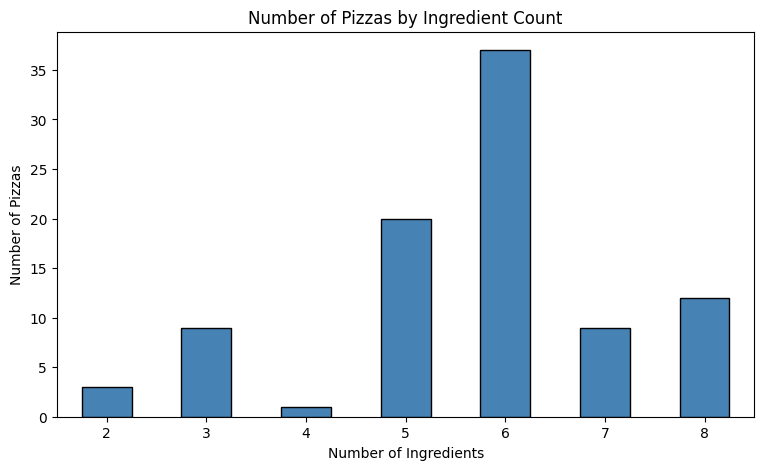

In [19]:
dist = ingredient_count_per_pizza.value_counts().sort_index()

plt.figure(figsize=(9,5))
dist.plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Number of Pizzas by Ingredient Count')
plt.xlabel('Number of Ingredients')
plt.ylabel('Number of Pizzas')
plt.xticks(rotation=0)
plt.show()

In [20]:
product_catalog.to_parquet('product_catalog', index=False)

## Explore orders

Sales per days 

In [21]:
orders = pd.read_parquet('orders')
orders.head()

,order_id,order_date,item_id,quantity
0,1,2015-01-01,1,1
1,2,2015-01-01,2,1
2,2,2015-01-01,3,1
3,2,2015-01-01,4,1
4,2,2015-01-01,5,1


In [22]:
print("Missing values per column:")
print(orders.isnull().sum())
print("Duplicate rows:", orders.duplicated().sum())

Missing values per column:
order_id      0
order_date    0
item_id       0
quantity      0
dtype: int64
Duplicate rows: 0


Theres no much cleaning needed to be done, just check the XXL and XL orders.

In [23]:
product_catalog[product_catalog['variant'].isin(['XL','XXL'])]["item_id"]

59    60
90    91
Name: item_id, dtype: int64

In [24]:
orders_to_remove = orders[orders['item_id'].isin([60,91])]
print("Total XL and XXL orders:",len(orders_to_remove))


Total XL and XXL orders: 572


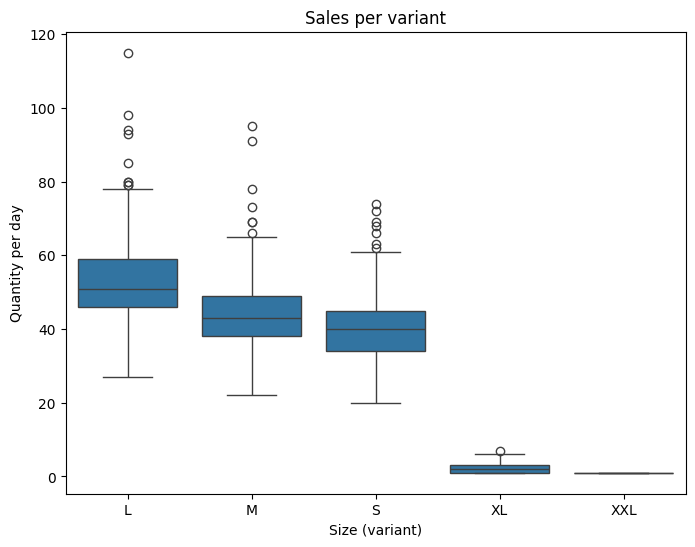

In [25]:
orders_with_variant = orders.merge(product_catalog[['item_id', 'variant']], on='item_id')
daily_by_variant = orders_with_variant.groupby(['order_date', 'variant'])['quantity'].sum().reset_index()

plt.figure(figsize=(8, 6))
sns.boxplot(data=daily_by_variant, x='variant', y='quantity')
plt.title('Sales per variant')
plt.xlabel('Size (variant)')
plt.ylabel('Quantity per day')
plt.show()

Prodcuts with XL and XXL will be removed as theres no need for them and they represent 1% of the toal orders.

In [26]:
print("Shape antes:", orders.shape)
orders = orders.drop(index=orders_to_remove.index).reset_index(drop=True)
print("Shape después:", orders.shape)

Shape antes: (48620, 4)
Shape después: (48048, 4)


In [27]:
print("First date:", orders['order_date'].min())
print("Last date:", orders['order_date'].max())
print("Total days in range:", (orders['order_date'].max() - orders['order_date'].min()).days + 1)

First date: 2015-01-01 00:00:00
Last date: 2015-12-31 00:00:00
Total days in range: 365


Items per order

In [28]:
items_per_order = orders.groupby('order_id').size()
items_per_order.describe()

count    21231.000000
mean         2.263106
std          1.691411
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         21.000000
dtype: float64

Orders consist of one item mostly

In [29]:
orders['quantity'].value_counts().sort_index()

quantity
1    47129
2      895
3       21
4        3
Name: count, dtype: int64

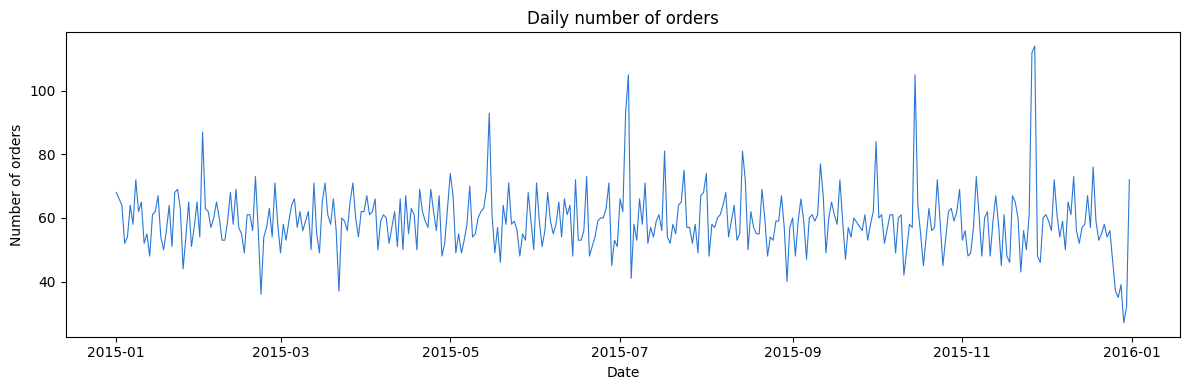

In [30]:
daily_orders = orders.groupby(orders['order_date'].dt.normalize())['order_id'].nunique()

plt.figure(figsize=(12, 4))
plt.plot(daily_orders.index, daily_orders.values, linewidth=0.8, color='#2a78d6')
plt.title('Daily number of orders')
plt.xlabel('Date')
plt.ylabel('Number of orders')
plt.tight_layout()
plt.show()

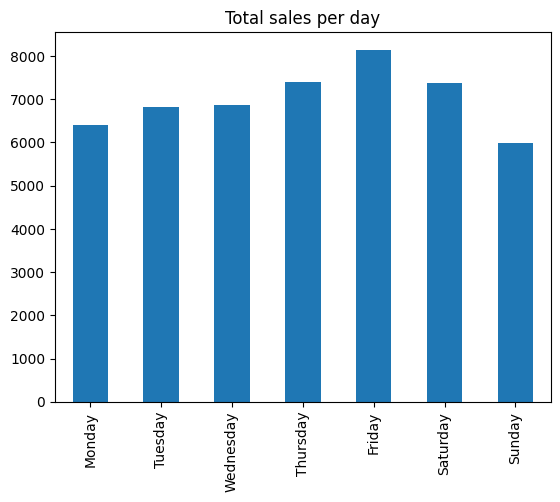

In [31]:
orders['day_of_week'] = orders['order_date'].dt.dayofweek
sales_by_dow = orders.groupby('day_of_week')['quantity'].sum()
sales_by_dow.index = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
sales_by_dow.plot(kind='bar', title='Total sales per day')
plt.show()

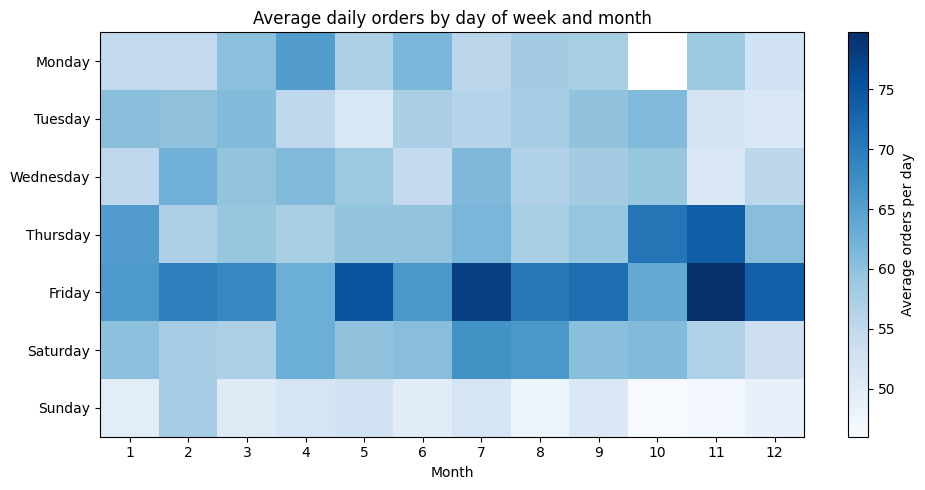

In [32]:
# We need this to see if the weekly pattern changes across the year
# This justifies using both day-of-week and month as separate cyclical features

daily = orders.groupby(orders['order_date'].dt.normalize())['order_id'].nunique().reset_index()
daily.columns = ['date', 'n_orders']
daily['day_of_week'] = daily['date'].dt.day_name()
daily['month'] = daily['date'].dt.month

pivot = daily.pivot_table(
    index='day_of_week',
    columns='month',
    values='n_orders',
    aggfunc='mean'
).reindex(['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])

plt.figure(figsize=(10, 5))
plt.imshow(pivot, cmap='Blues', aspect='auto')
plt.colorbar(label='Average orders per day')
plt.xticks(range(len(pivot.columns)), pivot.columns)
plt.yticks(range(len(pivot.index)), pivot.index)
plt.title('Average daily orders by day of week and month')
plt.xlabel('Month')
plt.tight_layout()
plt.show()

Intermittent and low-volume demand.

Basicually check the sales per product.

In [33]:
daily_sales = (orders.groupby(["item_id", "order_date"])["quantity"].sum().reset_index())

# Create a full grid of all days orders
all_items = daily_sales["item_id"].unique()
all_dates = pd.date_range(daily_sales["order_date"].min(), daily_sales["order_date"].max(), freq="D")

full_grid = pd.MultiIndex.from_product(
    [all_items, all_dates], names=["item_id", "order_date"]
).to_frame(index=False)

# Merge with the real sales and ad 0 
full_grid = full_grid.merge(daily_sales, on=["item_id", "order_date"], how="left")
full_grid["quantity"] = full_grid["quantity"].fillna(0)

In [34]:
# Calculate the percentage of days with 0 sales 
pct_zero_days = (full_grid["quantity"] == 0).mean() * 100
print(f"%Percentage of product day with zero demand: {pct_zero_days:.2f}%")

%Percentage of product day with zero demand: 30.22%


In [35]:
# calculate mean and median pero product
per_product_stats = (
    full_grid.groupby("item_id")["quantity"]
    .agg(mean_daily_demand="mean", median_daily_demand="median", pct_zero=lambda x: (x == 0).mean() * 100)
    .reset_index()
)
print(per_product_stats.sort_values("mean_daily_demand").head())

    item_id  mean_daily_demand  median_daily_demand   pct_zero
48       49           0.260274                  0.0  77.534247
46       47           0.263014                  0.0  76.986301
84       86           0.271233                  0.0  76.986301
15       16           0.443836                  0.0  65.753425
83       85           0.515068                  0.0  61.095890


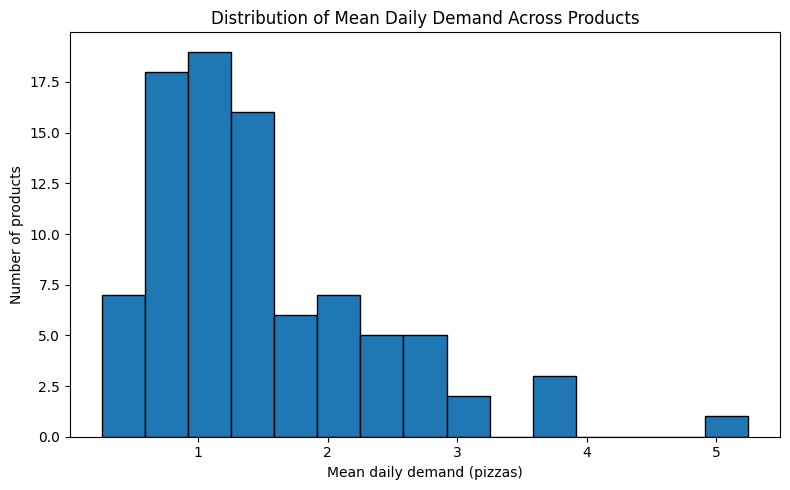

In [36]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(per_product_stats["mean_daily_demand"], bins=15, edgecolor="black")
ax.set_xlabel("Mean daily demand (pizzas)")
ax.set_ylabel("Number of products")
ax.set_title("Distribution of Mean Daily Demand Across Products")
plt.tight_layout()
plt.savefig("mean_daily_demand_distribution.png", dpi=150)
plt.show()

# Part 3: Algorithms 

## Format daily Orders

In [37]:
orders = pd.read_parquet('orders')
orders.head()

,order_id,order_date,item_id,quantity
0,1,2015-01-01,1,1
1,2,2015-01-01,2,1
2,2,2015-01-01,3,1
3,2,2015-01-01,4,1
4,2,2015-01-01,5,1


Compress orders geting only one entry per item per day 

In [38]:
daily_sales = (
    orders.groupby(['order_date', 'item_id'])['quantity']
    .sum()
    .reset_index()
    .rename(columns={'order_date': 'date'})
)
print(orders.shape)
print(daily_sales.shape)

(48620, 4)
(22964, 3)


In [39]:
daily_sales.head()

,date,item_id,quantity
0,2015-01-01,1,1
1,2015-01-01,2,7
2,2015-01-01,3,7
3,2015-01-01,4,6
4,2015-01-01,5,2


Dates were an item was not sold are added with a 0, creating a continous date column per item 

In [40]:
all_dates = pd.date_range(daily_sales['date'].min(), daily_sales['date'].max())
all_items = orders['item_id'].unique()

full_index = pd.MultiIndex.from_product([all_dates, all_items], names=['date', 'item_id'])

daily_sales = (
    daily_sales
    .set_index(['date', 'item_id'])
    .reindex(full_index, fill_value=0)
    .reset_index()
)

daily_sales.shape

(33215, 3)

Extra columns that will bring value to the dataset are added.
First the date is splited to know the mont and wich day of the week was that day.

In [41]:
daily_sales['month'] = daily_sales['date'].dt.month
daily_sales['day_of_week'] = daily_sales['date'].dt.dayofweek # 0 = Monday - 6 = Sunday

Weekends and bank holidays are usually buisier so identifying them can improve the algorithm.

In [42]:
print(daily_sales["date"].max())
print(daily_sales["date"].min())

import holidays

# US bank holidays as the dataSet comes from a pizza place in New York
holidays = holidays.US(state="NY", years=2015) 

daily_sales['weekend_holiday'] = daily_sales['day_of_week'].isin([5, 6]) | daily_sales['date'].isin(holidays)

2015-12-31 00:00:00
2015-01-01 00:00:00


Sales are also affected by the weather of each day. The nex blocks will load the weather for each day so later it can be clasiffied in a scale of 0 (bad) - 5 (good)

The data set is from an American pizzeria from New York 

In [43]:
import requests

url = "https://archive-api.open-meteo.com/v1/archive"
params = {
    "latitude": 40.7357,
    "longitude": -74.1724,
    "start_date": "2015-01-01",
    "end_date": "2015-12-31",
    "daily": "temperature_2m_max,temperature_2m_min,precipitation_sum",
    "timezone": "America/New_York"
}

response = requests.get(url, params=params)
weather_data = response.json()

weather_df = pd.DataFrame({
    'date': pd.to_datetime(weather_data['daily']['time']),
    'temp_max': weather_data['daily']['temperature_2m_max'],
    'temp_min': weather_data['daily']['temperature_2m_min'],
    'precip': weather_data['daily']['precipitation_sum']
})

weather_df['temp_avg'] = (weather_df['temp_max'] + weather_df['temp_min']) / 2
weather_df.head()

,date,temp_max,temp_min,precip,temp_avg
0,2015-01-01,2.6,-4.6,0.0,-1.00
1,2015-01-02,5.5,-2.4,0.0,1.55
2,2015-01-03,6.5,-2.9,17.9,1.80
3,2015-01-04,13.5,5.7,7.3,9.60
4,2015-01-05,6.8,-3.8,0.0,1.50


Exploring 'weather_df' 

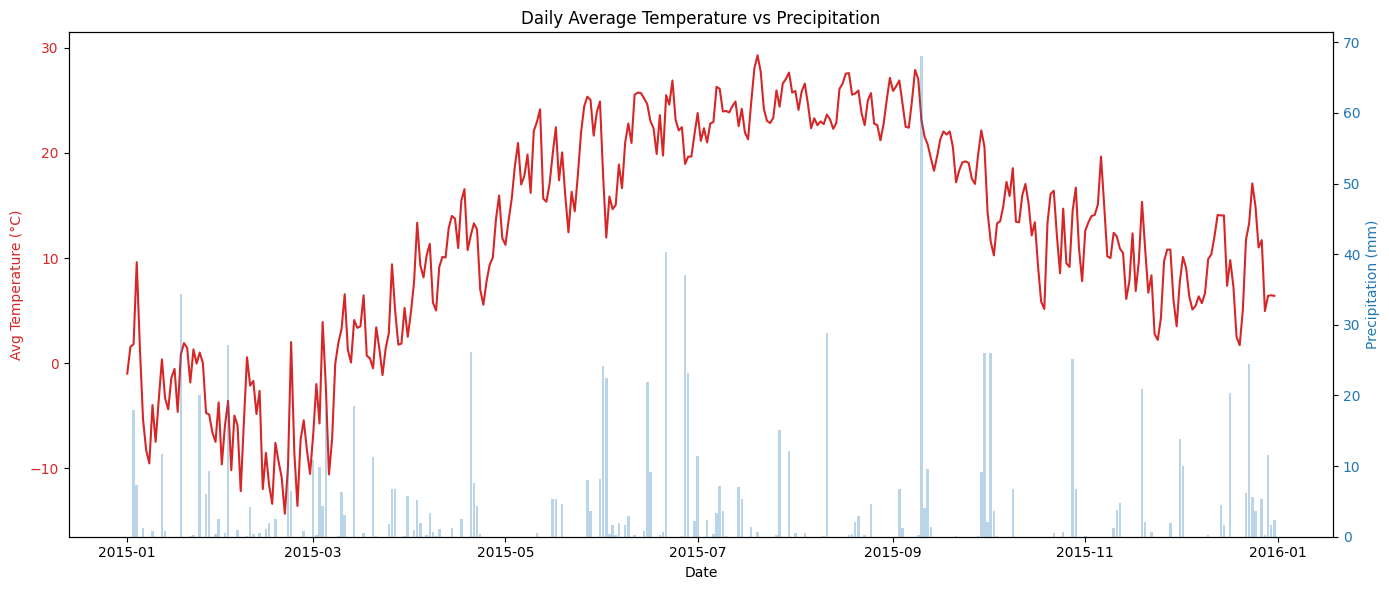

In [44]:
fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.plot(weather_df['date'], weather_df['temp_avg'], color='tab:red', label='Avg Temp (°C)')
ax1.set_xlabel('Date')
ax1.set_ylabel('Avg Temperature (°C)', color='tab:red')
ax1.tick_params(axis='y', labelcolor='tab:red')

ax2 = ax1.twinx()
ax2.bar(weather_df['date'], weather_df['precip'], color='tab:blue', alpha=0.3, label='Precipitation (mm)')
ax2.set_ylabel('Precipitation (mm)', color='tab:blue')
ax2.tick_params(axis='y', labelcolor='tab:blue')

plt.title('Daily Average Temperature vs Precipitation')
fig.tight_layout()
plt.show()

Temperature and precipitation values can not be interpretable as "good" or "bad" therefore both variables were converted into sub-scores on a 0-5 scale:

- Temperature score: peaks at 5 for a comfortable range (18-26°C), and decreases toward
  0 as temperatures move toward extreme cold or heat.
- Precipitation score: peaks at 5 for little to no rain, and decreases as daily
  precipitation increases.

These two scores will be combined into a single rounded score (weighted 60% temperature,
40% precipitation)

In [45]:
def temp_score(t):
    if 18 <= t <= 26:
        return 5
    elif 14 <= t < 18 or 26 < t <= 30:
        return 4
    elif 10 <= t < 14 or 30 < t <= 34:
        return 2
    else:
        return 0

def precip_score(p):
    if p < 1:
        return 5
    elif p < 3:
        return 3
    elif p < 6:
        return 1
    else:
        return 0

weather_df['temp_score'] = weather_df['temp_avg'].apply(temp_score)
weather_df['precip_score'] = weather_df['precip'].apply(precip_score)

weather_df['weather'] = (
    weather_df['temp_score'] * 0.6 + weather_df['precip_score'] * 0.4
).round().clip(0, 5).astype(int)

weather_df[['date', 'temp_avg', 'precip', 'weather']].head()

,date,temp_avg,precip,weather
0,2015-01-01,-1.00,0.0,2
1,2015-01-02,1.55,0.0,2
2,2015-01-03,1.80,17.9,0
3,2015-01-04,9.60,7.3,0
4,2015-01-05,1.50,0.0,2


Add the calculated weather column to 'daily_sales'.

In [46]:
daily_sales = daily_sales.merge(weather_df[['date', 'weather']], on='date')
daily_sales.head()

,date,item_id,quantity,month,day_of_week,weekend_holiday,weather
0,2015-01-01,1,1,1,3,False,2
1,2015-01-01,2,7,1,3,False,2
2,2015-01-01,3,7,1,3,False,2
3,2015-01-01,4,6,1,3,False,2
4,2015-01-01,5,2,1,3,False,2


In [47]:
daily_sales = daily_sales[['date', 'month', 'day_of_week', 'weekend_holiday', 'weather', 'item_id', 'quantity']]
daily_sales.head()

,date,month,day_of_week,weekend_holiday,weather,item_id,quantity
0,2015-01-01,1,3,False,2,1,1
1,2015-01-01,1,3,False,2,2,7
2,2015-01-01,1,3,False,2,3,7
3,2015-01-01,1,3,False,2,4,6
4,2015-01-01,1,3,False,2,5,2


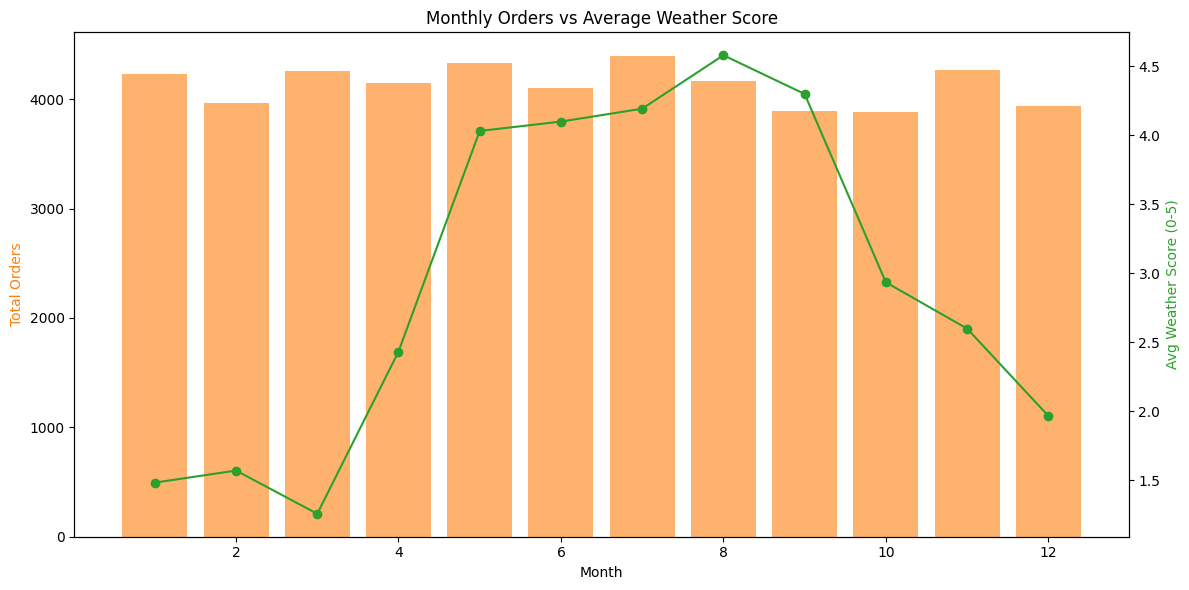

In [48]:
weather_df['temp_score'] = weather_df['temp_avg'].apply(temp_score)
weather_df['precip_score'] = weather_df['precip'].apply(precip_score)
weather_df['weather'] = (weather_df['temp_score']*0.6 + weather_df['precip_score']*0.4).round().clip(0,5).astype(int)

# Monthly sales
monthly_orders = daily_sales.copy()
monthly_orders['month'] = pd.to_datetime(monthly_orders['date']).dt.month
monthly_totals = monthly_orders.groupby('month')['quantity'].sum()

# Monthly weather score
weather_df['month'] = weather_df['date'].dt.month
monthly_weather = weather_df.groupby('month')['weather'].mean()

fig, ax1 = plt.subplots(figsize=(12,6))
ax1.bar(monthly_totals.index, monthly_totals.values, color='tab:orange', alpha=0.6, label='Total Orders')
ax1.set_xlabel('Month')
ax1.set_ylabel('Total Orders', color='tab:orange')

ax2 = ax1.twinx()
ax2.plot(monthly_weather.index, monthly_weather.values, color='tab:green', marker='o', label='Avg Weather Score')
ax2.set_ylabel('Avg Weather Score (0-5)', color='tab:green')

plt.title('Monthly Orders vs Average Weather Score')
fig.tight_layout()
plt.show()

Save the progress made so far

In [49]:
daily_sales.to_parquet('daily_sales', index=False)

## Clean daily sales and format

In [50]:
daily_sales = pd.read_parquet('daily_sales')

Lag features and will be computed per item. These features will show quantity sold the previous day (short-term momentum) and quantity sold on the same day of the previous week (weekly seasonality)

In [51]:
daily_sales = daily_sales.sort_values(['item_id', 'date']).reset_index(drop=True)

daily_sales['lag_1'] = daily_sales.groupby('item_id')['quantity'].shift(1)
daily_sales['lag_7'] = daily_sales.groupby('item_id')['quantity'].shift(7)

daily_sales.head(10)

,date,month,day_of_week,weekend_holiday,weather,item_id,quantity,lag_1,lag_7
0,2015-01-01,1,3,False,2,1,1,NaN,NaN
1,2015-01-02,1,4,False,2,1,1,1.0,NaN
2,2015-01-03,1,5,True,0,1,2,1.0,NaN
3,2015-01-04,1,6,True,0,1,1,2.0,NaN
4,2015-01-05,1,0,False,2,1,0,1.0,NaN
5,2015-01-06,1,1,False,1,1,2,0.0,NaN
6,2015-01-07,1,2,False,2,1,1,2.0,NaN
7,2015-01-08,1,3,False,2,1,0,1.0,1.0
8,2015-01-09,1,4,False,2,1,1,0.0,1.0
9,2015-01-10,1,5,True,2,1,1,1.0,2.0


Drop the first 7 days for each product as they will have and empty lag 

In [52]:
daily_sales_clean = daily_sales.dropna().reset_index(drop=True)
print(daily_sales.shape)
print(daily_sales_clean.shape)

(33215, 9)
(32578, 9)


item_id is a categorical identifier, for the LSTM, an embedding layer is
used instead of one-hot encoding: this lets the model learn a dense vector representation
of each product, capturing similarity between items (e.g., two pizzas with similar demand
patterns end up with similar embeddings) rather than treating every product as equally
unrelated to every other.

In [53]:
print("min item_id:", daily_sales_clean['item_id'].min())
print("max item_id:", daily_sales_clean['item_id'].max())
print("unique item_id:", daily_sales_clean['item_id'].nunique())

# Keras embeddings should start from 0 
daily_sales_clean['item_id_encoded'] = daily_sales_clean['item_id'] - daily_sales_clean['item_id'].min()

daily_sales_clean[['item_id', 'item_id_encoded']].drop_duplicates().head()

min item_id: 1
max item_id: 91
unique item_id: 91


,item_id,item_id_encoded
0,1,0
358,2,1
716,3,2
1074,4,3
1432,5,4


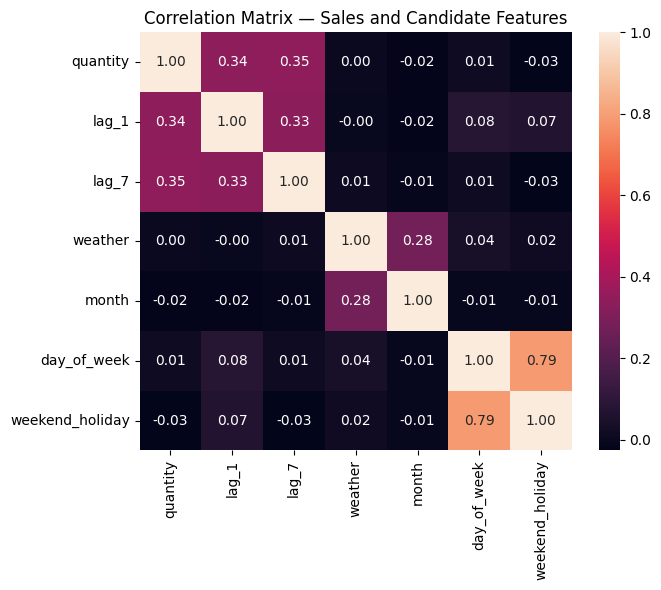

In [54]:
corr_cols = ['quantity', 'lag_1', 'lag_7', 'weather', 'month', 'day_of_week', 'weekend_holiday']
corr_matrix = daily_sales_clean[corr_cols].corr()
 
plt.figure(figsize=(7, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f')
plt.title('Correlation Matrix — Sales and Candidate Features')
plt.tight_layout()
plt.show()

## LSTM

Select 30 days as the cutoff date, meaning the last 30 days of the series will be used to test the model. Split the model based on that date.

In [55]:
test_days = 30
cutoff_date = daily_sales_clean['date'].max() - pd.Timedelta(days=test_days)

train_df = daily_sales_clean[daily_sales_clean['date'] <= cutoff_date].copy()
test_df = daily_sales_clean[daily_sales_clean['date'] > cutoff_date].copy()

print("Train shape:", train_df.shape, " from:", train_df['date'].min(), "-", train_df['date'].max())
print("Test shape:", test_df.shape, " from:", test_df['date'].min(), "-", test_df['date'].max())

Train shape: (29848, 10)  from: 2015-01-08 00:00:00 - 2015-12-01 00:00:00
Test shape: (2730, 10)  from: 2015-12-02 00:00:00 - 2015-12-31 00:00:00


Numeric features can't be used, thats why quantity and the lags will be scalated 

In [56]:
from sklearn.preprocessing import MinMaxScaler

numeric_features = ['quantity', 'lag_1', 'lag_7']

scaler = MinMaxScaler()
train_df[numeric_features] = scaler.fit_transform(train_df[numeric_features])
test_df[numeric_features] = scaler.transform(test_df[numeric_features])

train_df[numeric_features].describe()

,quantity,lag_1,lag_7
count,29848.000000,29848.000000,29848.000000
mean,0.099993,0.100009,0.099611
std,0.104155,0.104175,0.103455
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,0.066667,0.066667,0.066667
75%,0.133333,0.133333,0.133333
max,1.000000,1.000000,1.000000


*Cyclical Encoding*

day_of_week and month are cyclical values: Sunday and Monday are next to each other, and December and January are next to each. If we feed these numbers to the model as-is, it will wrongly think Sunday and Monday are very different days.

In [57]:
for df_ in [train_df, test_df]:
    df_['day_of_week_sin'] = np.sin(2 * np.pi * df_['day_of_week'] / 7)
    df_['day_of_week_cos'] = np.cos(2 * np.pi * df_['day_of_week'] / 7)
    df_['month_sin'] = np.sin(2 * np.pi * df_['month'] / 12)
    df_['month_cos'] = np.cos(2 * np.pi * df_['month'] / 12)

train_df.head()

,date,month,day_of_week,weekend_holiday,weather,item_id,quantity,lag_1,lag_7,item_id_encoded,day_of_week_sin,day_of_week_cos,month_sin,month_cos
0,2015-01-08,1,3,False,2,1,0.000000,0.066667,0.066667,0,0.433884,-0.900969,0.5,0.866025
1,2015-01-09,1,4,False,2,1,0.066667,0.000000,0.066667,0,-0.433884,-0.900969,0.5,0.866025
2,2015-01-10,1,5,True,2,1,0.066667,0.066667,0.133333,0,-0.974928,-0.222521,0.5,0.866025
3,2015-01-11,1,6,True,2,1,0.000000,0.066667,0.066667,0,-0.781831,0.623490,0.5,0.866025
4,2015-01-12,1,0,False,0,1,0.000000,0.000000,0.000000,0,0.000000,1.000000,0.5,0.866025


This step builds the sequences the LSTM will learn from. For each product, 14 days are taken in a row as input, and the next day's quantity as the answer to predict.
This is done separately for each item, so we never mix days from different products.

In [58]:
feature_cols = ['lag_1', 'lag_7', 'weekend_holiday', 'weather',
                 'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos']

# Combine scaled train_df and test_df 
full_scaled_df = pd.concat([train_df, test_df], ignore_index=True)
full_scaled_df = full_scaled_df.sort_values(['item_id_encoded', 'date']).reset_index(drop=True)


def build_sequences(df, cutoff_date, lookback):
    X_seq, X_item, y, dates = [], [], [], []

    for item_id, group in df.groupby('item_id_encoded'):
        group = group.sort_values('date').reset_index(drop=True)
        features = group[feature_cols].values
        target = group['quantity'].values
        target_dates = group['date'].values

        for i in range(lookback, len(group)):
            X_seq.append(features[i - lookback:i])
            X_item.append(item_id)
            y.append(target[i])
            dates.append(target_dates[i])

    X_seq, X_item, y, dates = np.array(X_seq), np.array(X_item), np.array(y), np.array(dates)

    # Check wether the date is train or test
    is_test = dates > np.datetime64(cutoff_date)
    return (X_seq[~is_test], X_item[~is_test], y[~is_test],
            X_seq[is_test], X_item[is_test], y[is_test])

(X_train_seq, X_train_item, y_train, X_test_seq, X_test_item, y_test) = build_sequences(full_scaled_df, cutoff_date, 14)

print("X_train_seq shape:", X_train_seq.shape)
print("X_train_item shape:", X_train_item.shape)
print("y_train shape:", y_train.shape)
print()
print("X_test_seq shape:", X_test_seq.shape)

X_train_seq shape: (28574, 14, 8)
X_train_item shape: (28574,)
y_train shape: (28574,)

X_test_seq shape: (2730, 14, 8)


Check that all arrays have the correct number type before training, to avoid mixed types theat can cause errors.


In [59]:
X_train_seq = X_train_seq.astype('float32')
X_train_item = X_train_item.astype('int32')
y_train = y_train.astype('float32')

X_test_seq = X_test_seq.astype('float32')
X_test_item = X_test_item.astype('int32')
y_test = y_test.astype('float32')

print(X_train_seq.dtype, X_train_item.dtype, y_train.dtype)

float32 int32 float32


For gettin reproducible results


In [60]:
import tensorflow as tf
np.random.seed(42)
tf.random.set_seed(42)

Builds the LSTM model. It has two inputs: the 14-day sequence of features, and the product id. 
The product id goes through an embedding layer so the model can learn how similar or different each product is. Both parts are combined to make the final prediction: the quantity for the next day.

In [61]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, Embedding, Flatten, Concatenate

n_items = daily_sales_clean['item_id_encoded'].nunique()
lookback = 14
n_features = X_train_seq.shape[2] # 8 features

# 1st input: features
seq_input = Input(shape=(lookback, n_features), name='sequence_input') # Define input shape
x = LSTM(64, return_sequences=True)(seq_input) # first lstm seq_input -> 64
x = LSTM(32)(x) # second lstm 64 (x) -> 32 "output"

# 2nd imput: item_id -> embedding
item_input = Input(shape=(1,), name='item_input')
item_embedding = Embedding(input_dim=n_items, output_dim=8)(item_input) # each product get a vector size 8
item_embedding = Flatten()(item_embedding)


# Combine 1st & 2nd 
combined = Concatenate()([x, item_embedding]) # vector size 40: 32 + 8

combined = Dense(16, activation='relu')(combined)
output = Dense(1)(combined) # final output after "combining" 40 numers and 2 dense 

model = Model(inputs=[seq_input, item_input], outputs=output)
model.compile(optimizer='adam', loss='mse', metrics=['mae'])

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ sequence_input      │ (None, 14, 8)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ item_input          │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 14, 64)    │     18,688 │ sequence_input[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 1, 8)      │        728 │ item_input[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 32)        │     12,416 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 8)         │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 40)        │          0 │ lstm_1[0][0],     │
│ (Concatenate)       │                   │            │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 16)        │        656 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │         17 │ dense[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 32,505 (126.97 KB)

 Trainable params: 32,505 (126.97 KB)

 Non-trainable params: 0 (0.00 B)

After running the model for a couple of times, a lower learning rate was added, so it learns more slowly and carefully instead of taking big steps avoiding overshoot.

In [62]:
from tensorflow.keras.optimizers import Adam

model.compile(optimizer=Adam(learning_rate=0.0005), loss='mse', metrics=['mae'])

10% of the training data gets separated and suffled to use for validation.

In [63]:
from sklearn.model_selection import train_test_split

X_seq_tr, X_seq_val, X_item_tr, X_item_val, y_tr, y_val = train_test_split(
    X_train_seq, X_train_item, y_train, test_size=0.1, random_state=42, shuffle=True
)

Train the model, adding an early stop if theres no improvement for 5 epochs in a row, keeping the best weights found.

In [64]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(
    [X_seq_tr, X_item_tr], y_tr,
    validation_data=([X_seq_val, X_item_val], y_val),
    epochs=50,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
804/804 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - loss: 0.0082 - mae: 0.0686 - val_loss: 0.0076 - val_mae: 0.0651
Epoch 2/50
804/804 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - loss: 0.0075 - mae: 0.0656 - val_loss: 0.0075 - val_mae: 0.0648
Epoch 3/50
804/804 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.0074 - mae: 0.0651 - val_loss: 0.0074 - val_mae: 0.0648
Epoch 4/50
804/804 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - loss: 0.0073 - mae: 0.0650 - val_loss: 0.0074 - val_mae: 0.0647
Epoch 5/50
804/804 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.0073 - mae: 0.0648 - val_loss: 0.0074 - val_mae: 0.0649
Epoch 6/50
804/804 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - loss: 0.0073 - mae: 0.0647 - val_loss: 0.0074 - val_mae: 0.0648
Epoch 7/50
804/804 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - loss: 0.0073 - mae: 0.0646 - val_loss: 0.0074 - val_mae: 0.0648
Epoch 8/50
804/804 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - loss: 0.0072 - mae: 0.0646 - val_loss: 0.0074 - val_mae: 0.0647
Epoch 9/50
804/804 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - l

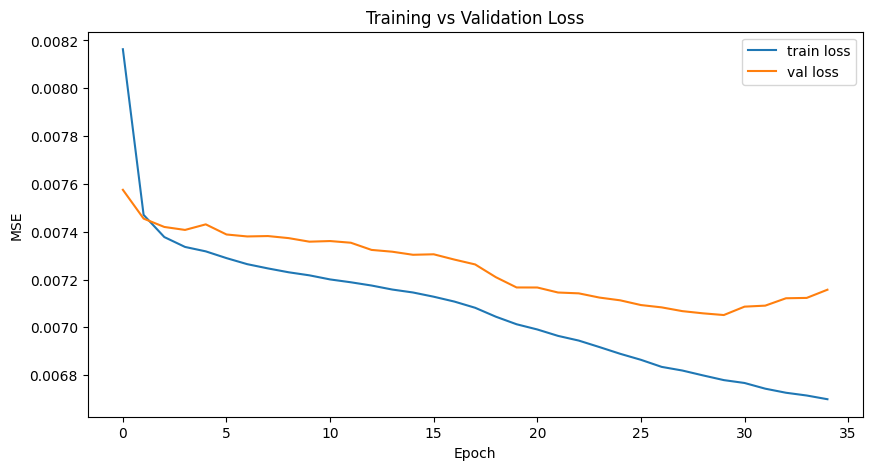

In [65]:
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE') #Mean Squared Error
plt.legend()
plt.show()

In [66]:
best_epoch = np.argmin(history.history['val_loss'])
print("Best eppoch (lower val_loss):", best_epoch)
print("Val loss for that epoch:", history.history['val_loss'][best_epoch])

Best eppoch (lower val_loss): 29
Val loss for that epoch: 0.007051529828459024


Test the model on unseen data (last 30 days for each product)

In [67]:
y_pred = model.predict([X_test_seq, X_test_item])

86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step


Calculate WAPE....

In [68]:
def wape(actual, predicted):
    return np.abs(actual - predicted).sum() / np.abs(actual).sum()

The sclaer was applied on quentity, lag_1 and lag_7. There fore an inverse transofrmer with the same 3 columns must be used.

In [69]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Re build arrays
dummy = np.zeros((len(y_test), 3))
dummy[:, 0] = y_test
y_test_real = scaler.inverse_transform(dummy)[:, 0]

dummy[:, 0] = y_pred.flatten()
y_pred_real = scaler.inverse_transform(dummy)[:, 0]

mae_lstm = mean_absolute_error(y_test_real, y_pred_real)
rmse_lstm = np.sqrt(mean_squared_error(y_test_real, y_pred_real))
wape_lstm = wape(y_test_real, y_pred_real)

print("Error on real numbers:")
print(f"LSTM - MAE: {mae_lstm:.2f} | RMSE: {rmse_lstm:.2f} | WAPE {wape_lstm:.2f}")

Error on real numbers:
LSTM - MAE: 0.95 | RMSE: 1.23 | WAPE 0.68


Looking at the error with real pizza counts per day, given that most products sell only a few units per day, this is a reasonably small error. 

## XGBoost

XGBoost does not need scaled features or 3D sequences. It needs a set of rows where each row is one day for one product, with lag and calendar features as regular columns. 

In [70]:
test_days = 30
cutoff_date = daily_sales_clean['date'].max() - pd.Timedelta(days=test_days)

train_df_xgb = daily_sales_clean[daily_sales_clean['date'] <= cutoff_date].copy()
test_df_xgb = daily_sales_clean[daily_sales_clean['date'] > cutoff_date].copy()

print("Train shape:", train_df_xgb.shape, " from:", train_df_xgb['date'].min(), "-", train_df_xgb['date'].max())
print("Test shape:", test_df_xgb.shape, " from:", test_df_xgb['date'].min(), "-", test_df_xgb['date'].max())

Train shape: (29848, 10)  from: 2015-01-08 00:00:00 - 2015-12-01 00:00:00
Test shape: (2730, 10)  from: 2015-12-02 00:00:00 - 2015-12-31 00:00:00


Cyclical encoding for dates, same as previous 

In [71]:
for df_ in [train_df_xgb, test_df_xgb]:
    df_['day_of_week_sin'] = np.sin(2 * np.pi * df_['day_of_week'] / 7)
    df_['day_of_week_cos'] = np.cos(2 * np.pi * df_['day_of_week'] / 7)
    df_['month_sin'] = np.sin(2 * np.pi * df_['month'] / 12)
    df_['month_cos'] = np.cos(2 * np.pi * df_['month'] / 12)

All features (x) are treated the same, incluing item_id, as this is a dessiiosn tree based algorithm. The only feature separates is quantity wich will be the target (y).

In [72]:
xgb_features = ['item_id', 'lag_1', 'lag_7', 'weekend_holiday', 'weather',
                 'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos']

X_train_xgb = train_df_xgb[xgb_features]
y_train_xgb = train_df_xgb['quantity']

X_test_xgb = test_df_xgb[xgb_features]
y_test_xgb = test_df_xgb['quantity']

X_train_xgb.head()

,item_id,lag_1,lag_7,weekend_holiday,weather,day_of_week_sin,day_of_week_cos,month_sin,month_cos
0,1,1.0,1.0,False,2,0.433884,-0.900969,0.5,0.866025
1,1,0.0,1.0,False,2,-0.433884,-0.900969,0.5,0.866025
2,1,1.0,2.0,True,2,-0.974928,-0.222521,0.5,0.866025
3,1,1.0,1.0,True,2,-0.781831,0.623490,0.5,0.866025
4,1,0.0,0.0,False,0,0.000000,1.000000,0.5,0.866025


Import XGBoost library and train the model.

In [73]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=200,       # controls how many trees are built (each one correcting the previous ones errors)
    max_depth=5,            # limits how complex each individual tree can be
    learning_rate=0.05,     # controls how much each tree contributes to the final prediction
    random_state=42
)

xgb_model.fit(X_train_xgb, y_train_xgb)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


This step evaluates the trained model on the test set, using the same MAE/RMSE metrics
as the LSTM so results can be compared directly. Since XGBoost was trained on raw
(unscaled) quantity values, no inverse-transform step is needed here.

In [74]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

y_pred_xgb = xgb_model.predict(X_test_xgb)

mae_xgb = mean_absolute_error(y_test_xgb, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test_xgb, y_pred_xgb))
wape_xgb = wape(y_test_xgb, y_pred_xgb)

print(f"XGBoost - MAE: {mae_xgb:.2f} | RMSE: {rmse_xgb:.2f} | WAPE {wape_xgb:.2f}")

XGBoost - MAE: 0.97 | RMSE: 1.25 | WAPE 0.69


## Prophet Model

Prophet is a forecasting library that utomatically models trend, weekly seasonality, and yearly seasonality from just two columns (date and value).
Since Prophet fits one model per time series, it is trained separately for each product (item_id), unlike XGBoost/LSTM which share one model across all products.

In [75]:
from prophet import Prophet

C:\Users\eduar\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [76]:
daily_sales = pd.read_parquet('daily_sales')

Prophet can be run with just two columns `ds` (date) and `y` (the value to predict). 
Additional regressors will be added.

In [77]:
def prepare_prophet_data_with_regressors(df, item_id):
    item_df = df[df['item_id'] == item_id][['date', 'quantity', 'weekend_holiday', 'weather']].copy()
    item_df = item_df.rename(columns={'date': 'ds', 'quantity': 'y'})
    item_df['weekend_holiday'] = item_df['weekend_holiday'].astype(int)  # Prophet needs numeric, not bool
    return item_df.sort_values('ds')

In [78]:
prophet_reg_predictions = []

for item_id in daily_sales_clean['item_id'].unique():
    train_item = prepare_prophet_data_with_regressors(train_df_xgb, item_id)

    if len(train_item) < 10:
        continue

    model = Prophet(yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False)
    model.add_regressor('weekend_holiday')
    model.add_regressor('weather')
    model.fit(train_item)

    test_item = prepare_prophet_data_with_regressors(test_df_xgb, item_id)
    future = test_item[['ds', 'weekend_holiday', 'weather']]

    forecast = model.predict(future)

    result = test_item[['ds', 'y']].copy()
    result['item_id'] = item_id
    result['yhat'] = forecast['yhat'].values
    prophet_reg_predictions.append(result)

prophet_results = pd.concat(prophet_reg_predictions, ignore_index=True)


21:32:13 - cmdstanpy - INFO - Chain [1] start processing
21:32:14 - cmdstanpy - INFO - Chain [1] done processing
21:32:14 - cmdstanpy - INFO - Chain [1] start processing
21:32:14 - cmdstanpy - INFO - Chain [1] done processing
21:32:14 - cmdstanpy - INFO - Chain [1] start processing
21:32:14 - cmdstanpy - INFO - Chain [1] done processing
21:32:15 - cmdstanpy - INFO - Chain [1] start processing
21:32:15 - cmdstanpy - INFO - Chain [1] done processing
21:32:15 - cmdstanpy - INFO - Chain [1] start processing
21:32:15 - cmdstanpy - INFO - Chain [1] done processing
21:32:15 - cmdstanpy - INFO - Chain [1] start processing
21:32:15 - cmdstanpy - INFO - Chain [1] done processing
21:32:16 - cmdstanpy - INFO - Chain [1] start processing
21:32:16 - cmdstanpy - INFO - Chain [1] done processing
21:32:16 - cmdstanpy - INFO - Chain [1] start processing
21:32:16 - cmdstanpy - INFO - Chain [1] done processing
21:32:17 - cmdstanpy - INFO - Chain [1] start processing
21:32:17 - cmdstanpy - INFO - Chain [1]

In [79]:
prophet_results.head()

,ds,y,item_id,yhat
0,2015-12-02,1,1,2.303962
1,2015-12-03,2,1,2.583391
2,2015-12-04,1,1,2.616310
3,2015-12-05,1,1,2.956386
4,2015-12-06,2,1,2.571857


In [80]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae_prophet = mean_absolute_error(prophet_results['y'], prophet_results['yhat'])
rmse_prophet = np.sqrt(mean_squared_error(prophet_results['y'], prophet_results['yhat']))
wape_prophet = wape(prophet_results['y'], prophet_results['yhat'])

print(f"Prophet - MAE: {mae_prophet:.2f} | RMSE: {rmse_prophet:.2f} | WAPE: {wape_prophet:.2f}")

Prophet - MAE: 1.20 | RMSE: 1.66 | WAPE: 0.86


## Random Forest 

Random Forest is another tree-based ensemble method, but instead of building trees
sequentially where each one corrects the previous one's errors (like XGBoost), it builds
many independent trees on random subsets of the data and features, then averages their
predictions. It reuses the same flat feature table already built for XGBoost.

In [81]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_xgb, y_train_xgb)

,n_estimators,200
,criterion,'squared_error'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


Run the model

In [82]:
y_pred_rf = rf_model.predict(X_test_xgb)

In [83]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae_rf = mean_absolute_error(y_test_xgb, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test_xgb, y_pred_rf))
wape_rf = wape(y_test_xgb, y_pred_rf)

print(f"Random Forest - MAE: {mae_rf:.2f} | RMSE: {rmse_rf:.2f} | WAPE: {wape_rf:.2f}")

Random Forest - MAE: 0.97 | RMSE: 1.26 | WAPE: 0.70


## Baseline Models

Simple forecasting baselines. This helps determine whether the added complexity of machine learning and deep learning models translates into a meaningful improvement in accuracy, or whether a much simpler approach could achieve comparable results, as both baselines require no training process and no hyperparameters

Historical mean baseline: for each product, the average daily demand observed in the training set is used as a constant prediction for every day in the test period.

In [84]:
# Media per producto
product_mean = train_df_xgb.groupby("item_id")["quantity"].mean().rename("pred_mean")

# Apply this metric to all the producst 
test_mean_baseline = test_df_xgb.merge(product_mean, on="item_id", how="left")
test_mean_baseline["error"] = test_mean_baseline["quantity"] - test_mean_baseline["pred_mean"]

mae_mean = test_mean_baseline["error"].abs().mean()
rmse_mean = np.sqrt((test_mean_baseline["error"] ** 2).mean())
wape_mean = wape(test_mean_baseline["quantity"], test_mean_baseline["pred_mean"])

print(f"Historical mean baseline — MAE: {mae_mean:.3f} | RMSE: {rmse_mean:.3f} | WAPE: {wape_mean:.3f}")

Historical mean baseline — MAE: 0.939 | RMSE: 1.211 | WAPE: 0.674


Seasonal naive baseline (lag 7): the prediction for a given day is simply the actual demand observed exactly 7 days earlier for that same product. This baseline captures weekly seasonality directly, under the assumption that demand this week will resemble demand the same day last week.

In [85]:
test_naive = train_df_xgb.copy()
test_naive["error"] = test_naive["quantity"] - test_naive["lag_7"]

mae_naive = test_naive["error"].abs().mean()
rmse_naive = np.sqrt((test_naive["error"] ** 2).mean())
wape_naive = wape(test_naive["quantity"], test_naive["lag_7"])

print(f"Seasonal naive (lag 7) baseline — MAE: {mae_naive:.3f} | RMSE: {rmse_naive:.3f} | WAPE: {wape_naive:.4f}")

Seasonal naive (lag 7) baseline — MAE: 1.272 | RMSE: 1.780 | WAPE: 0.8483


# Part 4: Comparing Results

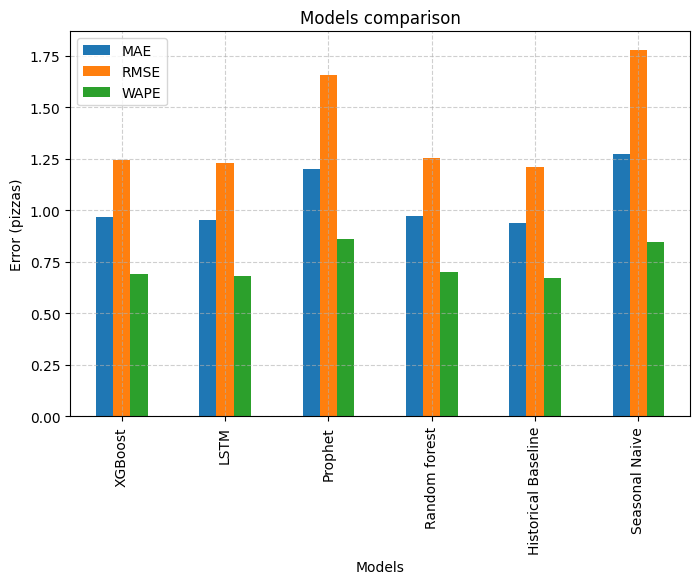

In [86]:
comparison_df = pd.DataFrame({
    'Models': ['XGBoost', 'LSTM', 'Prophet', 'Random forest', 'Historical Baseline', 'Seasonal Naive' ],
    'MAE': [ mae_xgb, mae_lstm, mae_prophet, mae_rf, mae_mean, mae_naive],
    'RMSE': [rmse_xgb, rmse_lstm, rmse_prophet, rmse_rf, rmse_mean, rmse_naive],
    'WAPE': [wape_xgb, wape_lstm, wape_prophet, wape_rf, wape_mean, wape_naive]
})

comparison_df.plot(x='Models', y=['MAE', 'RMSE', 'WAPE'], kind='bar', figsize=(8,5))
plt.title('Models comparison')
plt.grid(True, linestyle='--', alpha=0.6)
plt.ylabel('Error (pizzas)')
plt.show()

In [87]:
errors_xgb = y_test_xgb - y_pred_xgb
errors_lstm = y_test_real - y_pred_real
errors_prophet = prophet_results['y'] - prophet_results['yhat']
errors_rf = y_test_xgb - y_pred_rf
errors_hist_mean = test_mean_baseline["quantity"] - test_mean_baseline["pred_mean"]
errors_seasonal_naive = test_naive["quantity"] - test_naive["lag_7"]

error_comparison = pd.DataFrame({
    'XGBoost': errors_xgb.reset_index(drop=True),
    'LSTM': pd.Series(errors_lstm),
    'Prophet': errors_prophet.reset_index(drop=True),
    'Random Forest': errors_rf.reset_index(drop=True),
    'Hist Baseline': errors_hist_mean.reset_index(drop=True),
    'Seasonal Naive': errors_seasonal_naive.reset_index(drop=True)
})

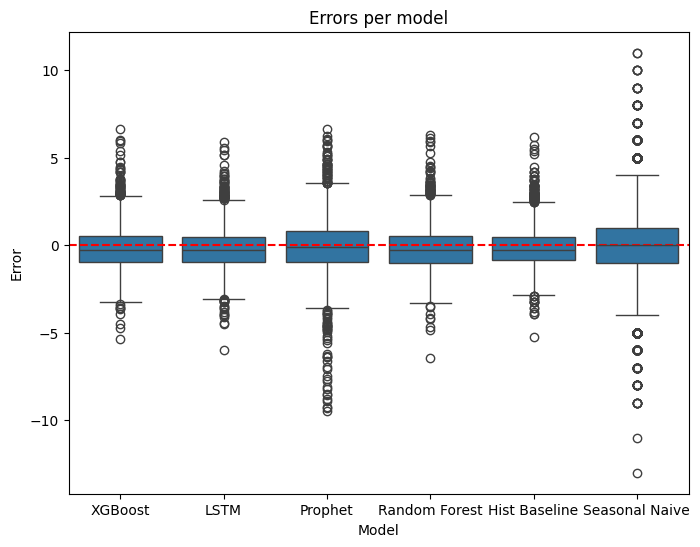

In [88]:
error_comparison_long = error_comparison.melt(var_name='Model', value_name='Error')

plt.figure(figsize=(8,6))
sns.boxplot(data=error_comparison_long, x='Model', y='Error')
plt.axhline(0, color='red', linestyle='--')
plt.title('Errors per model')
plt.show()

Training Time

This supports the decision to use XGBoost as the primary model: it matches both LSTM's and Random Forest's accuracy and consistency, while being simpler and faster to train than LSTM, more interpretable via feature importance, and clearly outperforms Prophet in both average error and error stability.

In [89]:
import time

start = time.time()
xgb_model.fit(X_train_xgb, y_train_xgb)
time_xgb = time.time() - start

print(f"XGBoost: {time_xgb:.1f}s")

XGBoost: 0.4s


In [90]:
start = time.time()
rf_model.fit(X_train_xgb, y_train_xgb)
time_rf = time.time() - start

print(f"Random Forest: {time_rf:.1f}s")

Random Forest: 1.3s


LSTM: 2 minutes 46s

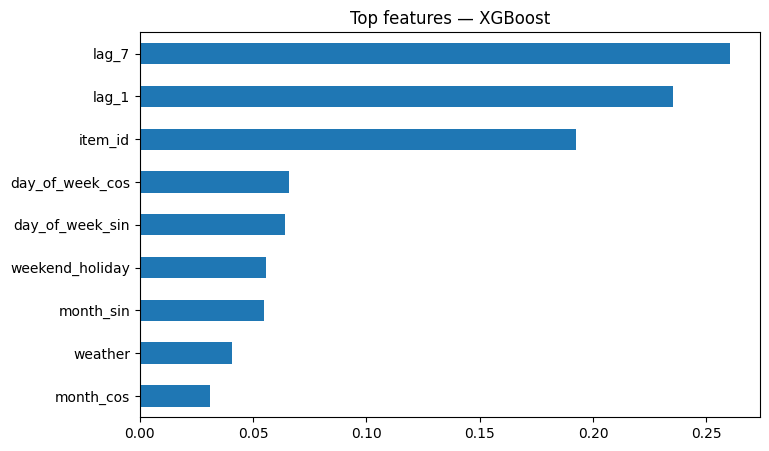

In [91]:
importances = pd.Series(xgb_model.feature_importances_, index=xgb_features).sort_values(ascending=False)

plt.figure(figsize=(8,5))
importances.plot(kind='barh')
plt.title('Top features — XGBoost')
plt.gca().invert_yaxis()
plt.show()

# Part 5: Impelent the algorithm to forcast a day

In [92]:
print("Last day on the dataset:")
print(test_df_xgb['date'].dt.date.max())

Last day on the dataset:
2015-12-31


Build a feature row for a date beyond the dataset (2016-01-01) for every product. This stops beeing an evaluation and turns into a forecast.

In [93]:
target_date = pd.Timestamp('2016-01-01')

lag_1_values = daily_sales_clean[daily_sales_clean['date'] == '2015-12-31'][['item_id', 'quantity']].rename(columns={'quantity': 'lag_1'}) # lag_1 = quantity from 2015-12-31
lag_7_values = daily_sales_clean[daily_sales_clean['date'] == '2015-12-25'][['item_id', 'quantity']].rename(columns={'quantity': 'lag_7'}) # lag_7 = quantity from 2015-12-25

future_df = lag_1_values.merge(lag_7_values, on='item_id')

future_df['month'] = target_date.month
future_df['day_of_week'] = target_date.dayofweek
future_df['weekend_holiday'] = True 

future_df['day_of_week_sin'] = np.sin(2 * np.pi * future_df['day_of_week'] / 7)
future_df['day_of_week_cos'] = np.cos(2 * np.pi * future_df['day_of_week'] / 7)
future_df['month_sin'] = np.sin(2 * np.pi * future_df['month'] / 12)
future_df['month_cos'] = np.cos(2 * np.pi * future_df['month'] / 12)

future_df.head()

,item_id,lag_1,lag_7,month,day_of_week,weekend_holiday,day_of_week_sin,day_of_week_cos,month_sin,month_cos
0,1,0,0,1,4,True,-0.433884,-0.900969,0.5,0.866025
1,2,5,0,1,4,True,-0.433884,-0.900969,0.5,0.866025
2,3,5,0,1,4,True,-0.433884,-0.900969,0.5,0.866025
3,4,2,0,1,4,True,-0.433884,-0.900969,0.5,0.866025
4,5,3,0,1,4,True,-0.433884,-0.900969,0.5,0.866025


The weather can´t be predicted that easy for future dates so use a regular date 3

In [94]:
future_df['weather'] = 3

future_df.head()

,item_id,lag_1,lag_7,month,day_of_week,weekend_holiday,day_of_week_sin,day_of_week_cos,month_sin,month_cos,weather
0,1,0,0,1,4,True,-0.433884,-0.900969,0.5,0.866025,3
1,2,5,0,1,4,True,-0.433884,-0.900969,0.5,0.866025,3
2,3,5,0,1,4,True,-0.433884,-0.900969,0.5,0.866025,3
3,4,2,0,1,4,True,-0.433884,-0.900969,0.5,0.866025,3
4,5,3,0,1,4,True,-0.433884,-0.900969,0.5,0.866025,3


Using the trained model of XGBoost calculate the date for the 91 pizzas 

In [95]:
future_features = future_df[xgb_features]

future_df['predicted_quantity'] = xgb_model.predict(future_features)

future_df[['item_id', 'predicted_quantity']].sort_values('predicted_quantity', ascending=False)

,item_id,predicted_quantity
2,3,4.586706
16,17,3.903758
1,2,3.796243
29,30,3.634142
27,28,3.388554
...,...,...
15,16,0.632894
14,15,0.632894
84,85,0.529347
85,86,0.425558


# Part 6: Implement a recursive forecast to forcast the next upcoming days

In [96]:
xgb_features = ['item_id', 'lag_1', 'lag_7', 'weekend_holiday', 'weather',
                 'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos']

def predict_next_day(next_date, ds_history, model):
    # Create the dataset for predicted day
    lag_1_df = ds_history[ds_history['date'] == next_date - pd.Timedelta(days=1)][['item_id', 'quantity']].rename(columns={'quantity': 'lag_1'})
    lag_7_df = ds_history[ds_history['date'] == next_date - pd.Timedelta(days=7)][['item_id', 'quantity']].rename(columns={'quantity': 'lag_7'})

    day_df = lag_1_df.merge(lag_7_df, on='item_id')
    day_df['month'] = next_date.month
    day_df['day_of_week'] = next_date.dayofweek
    day_df['weekend_holiday'] = next_date.dayofweek in [5, 6]  
    day_df['weather'] = 3  # using 3 as a default weather score

    day_df['day_of_week_sin'] = np.sin(2 * np.pi * day_df['day_of_week'] / 7)
    day_df['day_of_week_cos'] = np.cos(2 * np.pi * day_df['day_of_week'] / 7)
    day_df['month_sin'] = np.sin(2 * np.pi * day_df['month'] / 12)
    day_df['month_cos'] = np.cos(2 * np.pi * day_df['month'] / 12)

    day_df['predicted_quantity'] = model.predict(day_df[xgb_features])
    day_df['date'] = next_date
    return day_df

# Create ds_history with only 3 features
ds_history = daily_sales_clean[['date', 'item_id', 'quantity']].copy()

# Add past forecast
day1 = future_df[['item_id', 'predicted_quantity']].copy()
day1['date'] = pd.Timestamp('2016-01-01')
day1_for_lookup = day1.rename(columns={'predicted_quantity': 'quantity'})

# Forecast 2016-01-02
ds_history = pd.concat([ds_history, day1_for_lookup[['date', 'item_id', 'quantity']]], ignore_index=True)
day2 = predict_next_day(pd.Timestamp('2016-01-02'), ds_history, xgb_model)
day2_for_lookup = day2[['date','item_id','predicted_quantity']].rename(columns={'predicted_quantity':'quantity'})

# Forecast 2016-01-03
ds_history = pd.concat([ds_history, day2_for_lookup], ignore_index=True)
day3 = predict_next_day(pd.Timestamp('2016-01-03'), ds_history, xgb_model)

day2[['item_id', 'predicted_quantity']].head()

,item_id,predicted_quantity
0,1,1.534129
1,2,3.544185
2,3,4.508811
3,4,1.938903
4,5,1.108175


In [97]:
day3[['item_id', 'predicted_quantity']].head()

,item_id,predicted_quantity
0,1,1.136235
1,2,2.652855
2,3,3.776410
3,4,1.727518
4,5,1.240394


# Part 7: Confidence Levels for the three day forecast

Since the real forecasted days have no ground truth, we simulate the same recursive
process on the test set (where actual values are known), starting from multiple points,
to estimate the typical error at horizon 1, 2, and 3 days ahead.

In [98]:
test_dates = sorted(test_df_xgb['date'].unique())
horizon_errors_raw = {1: [], 2: [], 3: []}

for start_date in test_dates[:-3]:
    lookup_sim = daily_sales_clean[daily_sales_clean['date'] <= start_date][['date', 'item_id', 'quantity']].copy()

    for h in [1, 2, 3]:
        target_date = start_date + pd.Timedelta(days=h)
        pred_day = predict_next_day(target_date, lookup_sim, xgb_model)

        actual_day = daily_sales_clean[daily_sales_clean['date'] == target_date][['item_id', 'quantity']]
        merged = pred_day[['item_id', 'predicted_quantity']].merge(actual_day, on='item_id')

        errors = merged['quantity'] - merged['predicted_quantity']
        horizon_errors_raw[h].extend(errors.tolist())

        pred_for_lookup = pred_day[['date', 'item_id', 'predicted_quantity']].rename(columns={'predicted_quantity': 'quantity'})
        lookup_sim = pd.concat([lookup_sim, pred_for_lookup], ignore_index=True)


In [99]:
for h in [1, 2, 3]:
    errors_h = np.array(horizon_errors_raw[h])
    print(f"Horizon {h} day - Mean: {errors_h.mean():.3f} | Std: {errors_h.std():.3f}")

Horizon 1 day - Mean: -0.156 | Std: 1.235
Horizon 2 day - Mean: -0.145 | Std: 1.229
Horizon 3 day - Mean: -0.134 | Std: 1.244


Using a horizon method to calculate the confidence level. It uses the mean and standard deviation of the error at each horizon, a 95% confidence interval (±2 standard deviations) is applied to each forecasted day.

In [100]:
horizon_stats = {}
for h in [1, 2, 3]:
    errors_h = np.array(horizon_errors_raw[h])
    horizon_stats[h] = {'mean_error': errors_h.mean(), 'std_error': errors_h.std()}

horizon_stats

{1: {'mean_error': np.float64(-0.15638352107555342),
  'std_error': np.float64(1.2349899206948403)},
 2: {'mean_error': np.float64(-0.14463513303589035),
  'std_error': np.float64(1.229049551945867)},
 3: {'mean_error': np.float64(-0.13434168767361415),
  'std_error': np.float64(1.244025677327281)}}

Using the mean and standard deviation of the error at each horizon, a 95% confidence
interval (±2 standard deviations) is applied to each forecasted day.

In [101]:
forecast_with_confidence = pd.concat([
    day1[['date','item_id','predicted_quantity']],
    day2[['date','item_id','predicted_quantity']],
    day3[['date','item_id','predicted_quantity']]
], ignore_index=True).rename(columns={'predicted_quantity': 'quantity'})

horizon_by_date = {
    pd.Timestamp('2016-01-01'): 1,
    pd.Timestamp('2016-01-02'): 2,
    pd.Timestamp('2016-01-03'): 3,
}
forecast_with_confidence['horizon'] = forecast_with_confidence['date'].map(horizon_by_date)

forecast_with_confidence['lower_bound'] = forecast_with_confidence.apply(
    lambda row: row['quantity'] + horizon_stats[row['horizon']]['mean_error'] - 2*horizon_stats[row['horizon']]['std_error'],
    axis=1
)
forecast_with_confidence['upper_bound'] = forecast_with_confidence.apply(
    lambda row: row['quantity'] + horizon_stats[row['horizon']]['mean_error'] + 2*horizon_stats[row['horizon']]['std_error'],
    axis=1
)

forecast_with_confidence[['date', 'item_id', 'quantity', 'lower_bound', 'upper_bound']].round(2).head(10)

C:\Users\eduar\AppData\Local\Temp\ipykernel_26092\1828812474.py:23: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  forecast_with_confidence[['date', 'item_id', 'quantity', 'lower_bound', 'upper_bound']].round(2).head(10)


,date,item_id,quantity,lower_bound,upper_bound
0,2016-01-01,1,1.10,-1.53,3.41
1,2016-01-01,2,3.80,1.17,6.11
2,2016-01-01,3,4.59,1.96,6.90
3,2016-01-01,4,1.84,-0.78,4.16
4,2016-01-01,5,1.91,-0.72,4.22
5,2016-01-01,6,2.57,-0.06,4.88
6,2016-01-01,7,3.03,0.40,5.34
7,2016-01-01,8,1.11,-1.51,3.43
8,2016-01-01,9,1.28,-1.35,3.59
9,2016-01-01,10,0.94,-1.69,3.25


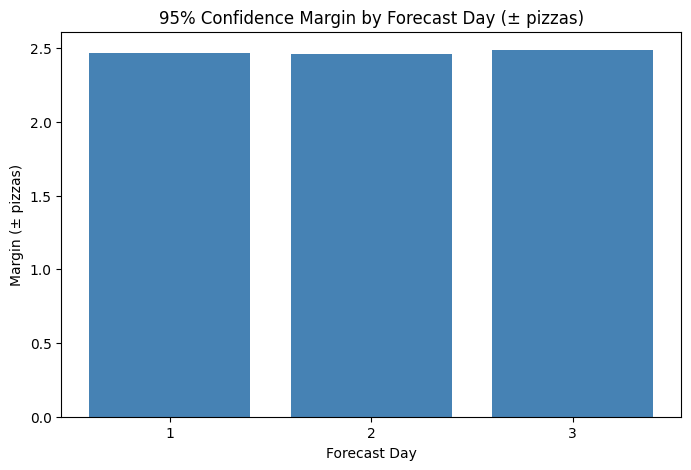

In [102]:
confidence_summary = pd.DataFrame({
    'horizon': ["1", "2", "3"],
    'mean_error': [horizon_stats[h]['mean_error'] for h in [1,2,3]],
    'std_error': [horizon_stats[h]['std_error'] for h in [1,2,3]],
})
confidence_summary['95%_margin'] = 2 * confidence_summary['std_error']

plt.figure(figsize=(8,5))
plt.bar(confidence_summary['horizon'], confidence_summary['95%_margin'], color='steelblue')
plt.title('95% Confidence Margin by Forecast Day (± pizzas)')
plt.ylabel('Margin (± pizzas)')
plt.xlabel('Forecast Day')
plt.show()



In [103]:
confidence_summary.round(2)

,horizon,mean_error,std_error,95%_margin
0,1,-0.16,1.23,2.47
1,2,-0.14,1.23,2.46
2,3,-0.13,1.24,2.49


Forcast: 4 pizzas

Margin 95%: ±2.45

Expected: between 4 - 0.17 - 2.45 = 1.38  and  4 - 0.17 + 2.45 = 6.28

# Part 8: Convert and format history + forecast & ingredients list to excel

### History

In [104]:
day1_final = day1[['date', 'item_id', 'predicted_quantity']].copy()
day2_final = day2[['date', 'item_id', 'predicted_quantity']].copy()
day3_final = day3[['date', 'item_id', 'predicted_quantity']].copy()

forecast_df = pd.concat([day1_final, day2_final, day3_final], ignore_index=True)
forecast_df = forecast_df.rename(columns={'predicted_quantity': 'quantity'})
forecast_df['is_forecast'] = True

forecast_df.shape

(273, 4)

In [105]:
ds_history = daily_sales_clean[['date', 'item_id', 'quantity']].copy()
ds_history['is_forecast'] = False

HF_sales_df = pd.concat([ds_history, forecast_df], ignore_index=True)
HF_sales_df = HF_sales_df.sort_values(['item_id', 'date']).reset_index(drop=True)

HF_sales_df.tail(10)

,date,item_id,quantity,is_forecast
32841,2015-12-25,91,0.000000,False
32842,2015-12-26,91,0.000000,False
32843,2015-12-27,91,0.000000,False
32844,2015-12-28,91,0.000000,False
32845,2015-12-29,91,0.000000,False
32846,2015-12-30,91,0.000000,False
32847,2015-12-31,91,0.000000,False
32848,2016-01-01,91,0.222344,True
32849,2016-01-02,91,0.206548,True
32850,2016-01-03,91,0.153234,True


Instead of having item_id add the pizza name and the size 

In [106]:
product_catalog = pd.read_parquet('product_catalog')

In [107]:
HF_sales_df = HF_sales_df.merge(
    product_catalog[['item_id', 'product_name', 'category', 'variant']], on='item_id'
)

HF_sales_df = HF_sales_df[['date', 'product_name', 'variant', 'category', 'quantity', 'is_forecast']]
HF_sales_df = HF_sales_df.sort_values(['date', 'product_name', 'variant']).reset_index(drop=True)

HF_sales_df.head()

,date,product_name,variant,category,quantity,is_forecast
0,2015-01-08,The Barbecue Chicken Pizza,L,Chicken,3.0,False
1,2015-01-08,The Barbecue Chicken Pizza,M,Chicken,3.0,False
2,2015-01-08,The Barbecue Chicken Pizza,S,Chicken,0.0,False
3,2015-01-08,The Big Meat Pizza,S,Classic,7.0,False
4,2015-01-08,The Brie Carre Pizza,S,Supreme,0.0,False


### Ingredients

The next list assumes ingredients in grams. This assumes a medium (M) pizza as the baseline unit.

In [108]:
ingredient_quantities = {
    # Base
    "Dough": 250,
    "Tomato Sauce": 80,

    # Sauces 
    "Barbecue Sauce": 70, "Alfredo Sauce": 70, "Pesto Sauce": 60,
    "Chipotle Sauce": 50, "Thai Sweet Chilli Sauce": 50,

    # Cheese
    "Mozzarella Cheese": 100, "Feta Cheese": 60,
    "Provolone Cheese": 60, "Smoked Gouda Cheese": 60,
    "Romano Cheese": 40, "Blue Cheese": 50,
    "Goat Cheese": 60, "Asiago Cheese": 50, "Fontina Cheese": 60,
    "Gouda Cheese": 60, "Ricotta Cheese": 60,
    "Gorgonzola Piccante Cheese": 50, "Parmigiano Reggiano Cheese": 40,
    "Brie Carre Cheese": 60,

    # Meets
    "Chicken": 100, "Barbecued Chicken": 100, "Sliced Ham": 80, "Pepperoni": 70,
    "Bacon": 60, "Calabrese Salami": 70, "Capocollo": 70, "Genoa Salami": 70,
    "Soppressata Salami": 70, "Coarse Sicilian Salami": 70, "Nduja Salami": 60,
    "Pancetta": 60, "Prosciutto di San Daniele": 60, "Prosciutto": 60,
    "Italian Sausage": 80, "Chorizo Sausage": 80, "Luganega Sausage": 80,
    "Beef Chuck Roast": 90, "Anchovies": 30,

    # Vegetables
    "Tomatoes": 40, "Plum Tomatoes": 40, "Sun-dried Tomatoes": 25,
    "Red Onions": 30, "Onions": 30, "Caramelized Onions": 30,
    "Red Peppers": 30, "Green Peppers": 30, "Jalapeno Peppers": 20,
    "Friggitello Peppers": 25, "Peperoncini verdi": 20, "Mushrooms": 40,
    "Spinach": 30, "Zucchini": 30, "Eggplant": 40, "Artichokes": 35,
    "Artichoke": 35, "Green Olives": 25, "Kalamata Olives": 25,
    "Pineapple": 40, "Corn": 25, "Pears": 30, "Arugula": 20,
    "Garlic": 8, "Oregano": 3, "Thyme": 3, "Cilantro": 8,
}

Since larger pizzas use more of each ingredient, a size multiplier is applied before
calculating total ingredient needs. This assumes a medium (M) pizza as the baseline unit.

In [109]:
size_multiplier = {
    'S': 0.75,
    'M': 1.00,
    'L': 1.25,
    'XL': 1.50,
    'XXL': 1.75
}

Ingredients per pizza are exploded and bases (Dough and Tomato Sause) are added. Then all ingredients are scaled.

In [110]:
recipe_by_item = product_catalog[['item_id', 'product_name', 'variant', 'ingredients']].copy()
recipe_by_item['ingredients_list'] = recipe_by_item['ingredients'].str.split(', ').apply(
    lambda ing_list: ["Dough", "Tomato Sauce"] + [i.strip() for i in ing_list]
)
recipe_by_item = recipe_by_item.explode('ingredients_list').rename(
    columns={'ingredients_list': 'ingredient'}
)

recipe_by_item['size_multiplier'] = recipe_by_item['variant'].map(size_multiplier)
recipe_by_item['base_quantity_g'] = recipe_by_item['ingredient'].map(ingredient_quantities)
recipe_by_item['ingredient_quantity_g'] = (
    recipe_by_item['base_quantity_g'] * recipe_by_item['size_multiplier']
)

recipe_by_item[['item_id', 'product_name', 'variant', 'ingredient', 'ingredient_quantity_g']].head()

,item_id,product_name,variant,ingredient,ingredient_quantity_g
0,1,The Hawaiian Pizza,M,Dough,250.0
0,1,The Hawaiian Pizza,M,Tomato Sauce,80.0
0,1,The Hawaiian Pizza,M,Sliced Ham,80.0
0,1,The Hawaiian Pizza,M,Pineapple,40.0
0,1,The Hawaiian Pizza,M,Mozzarella Cheese,100.0


Calculate ingredients per day

In [111]:

def ingredient_totals_for_day(day_df):
    # Join predicted quantity per item_id with its per-ingredient gram requirement
    merged = day_df[['item_id', 'predicted_quantity']].merge(
        recipe_by_item[['item_id', 'ingredient', 'ingredient_quantity_g']], on='item_id'
    )
    # Total grams needed = forecasted pizzas * grams per ingredient per pizza 
    merged['adjusted_quantity_g'] = (
        merged['predicted_quantity'] * merged['ingredient_quantity_g'] 
    )

    # Aggregate across all products sharing the same ingredient
    totals = (
        merged.groupby('ingredient')['adjusted_quantity_g']
        .sum()
        .round(2)
    )
    return totals

day1_ingredients = ingredient_totals_for_day(day1)
day2_ingredients = ingredient_totals_for_day(day2)
day3_ingredients = ingredient_totals_for_day(day3)

day1_ingredients.head()

ingredient
Alfredo Sauce    218.74
Anchovies        132.28
Artichoke        251.97
Artichokes       709.46
Arugula           87.67
Name: adjusted_quantity_g, dtype: float64

Ensure all three days share the same complete set of ingredients, filling with 0 where an ingredient has no requirement that day

In [112]:
all_ingredients = day1_ingredients.index.union(day2_ingredients.index).union(day3_ingredients.index)

day1_ingredients = day1_ingredients.reindex(all_ingredients, fill_value=0)
day2_ingredients = day2_ingredients.reindex(all_ingredients, fill_value=0)
day3_ingredients = day3_ingredients.reindex(all_ingredients, fill_value=0)

Create a final dataset with all the ingredients and they use per forcasted day 

In [113]:
ingredient_by_day = pd.DataFrame({
    'Ingredient': all_ingredients,
    'day_1': day1_ingredients.values,
    'day_2': day2_ingredients.values,
    'day_3': day3_ingredients.values,
})

ingredient_by_day['total'] = ingredient_by_day[['day_1', 'day_2', 'day_3']].sum(axis=1)
ingredient_by_day = ingredient_by_day.rename(
    columns={
        'day_1': day1["date"][:1].to_string()[4:],
        'day_2': day2["date"][:1].to_string()[4:],
        'day_3': day3["date"][:1].to_string()[4:],
    }
)

ingredient_by_day

,Ingredient,2016-01-01,2016-01-02,2016-01-03,total
0,Alfredo Sauce,218.74,194.38,142.39,555.51
1,Anchovies,132.28,120.79,107.97,361.04
2,Artichoke,251.97,227.67,197.83,677.47
3,Artichokes,709.46,610.74,524.30,1844.50
4,Arugula,87.67,86.90,64.65,239.22
...,...,...,...,...,...
62,Thai Sweet Chilli Sauce,277.89,349.92,292.00,919.81
63,Thyme,2.58,2.81,2.55,7.94
64,Tomato Sauce,12062.23,11347.63,9567.57,32977.43
65,Tomatoes,3452.76,3167.83,2717.31,9337.90


### Exporting Final Excel 

This creates a two-sheet Excel file: the first sheet shows the last 3 months of historical sales plus the 3-day forecast, and the second sheet shows the calculated ingredient requirements.

In [114]:
with pd.ExcelWriter('daily_sales_forecast.xlsx', engine='openpyxl') as writer:
    HF_sales_df.to_excel(writer, index=False, sheet_name='sales_last3months_forecast')
    ingredient_by_day.to_excel(writer, index=False, sheet_name='ingredient_forecast')

## Export XGBoost Algorithm

In [115]:
import pickle
with open('xgb_model.pkl', 'wb') as f:
    pickle.dump(xgb_model, f)